In [16]:
#Khai báo các thư viện/hàm cần dùng
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers

In [17]:
#Gọi hàm tiền xử lý ảnh
sys.path.append(str(Path.cwd().parent / 'src' / 'data'))
from preprocess import preprocess_image

In [18]:
#Đọc dữ liệu huấn luyện
data = pd.read_csv(str(Path.cwd().parent / 'data' / 'train.csv'))

In [19]:
#Kiểm tra dữ liệu
display(data.head())
print("Kích thước dữ liệu:", data.shape)

,Unnamed: 0,file_name,label
0,0,train_data/a6dcb93f596a43249135678dfcfc17ea.jpg,1
1,1,train_data/041be3153810433ab146bc97d5af505c.jpg,0
2,2,train_data/615df26ce9494e5db2f70e57ce7a3a4f.jpg,1
3,3,train_data/8542fe161d9147be8e835e50c0de39cd.jpg,0
4,4,train_data/5d81fa12bc3b4cea8c94a6700a477cf2.jpg,1


Kích thước dữ liệu: (79950, 3)


In [20]:
#Loại bỏ dòng thiếu thông tin và tên ảnh trùng lặp
data = data.dropna(subset=['file_name', 'label'])
data = data.drop_duplicates(subset=['file_name']).reset_index(drop=True)

In [22]:
#Loại bỏ ảnh không tồn tại
image_dir = Path('../data')
data = data[data['file_name'].apply(lambda f: (image_dir / f).is_file())]

In [23]:
#Tách dữ liệu thành tập Train (70%) và tập còn lại (30%)
dt_Train, dt_Temp = train_test_split(data, test_size=0.3, random_state=42, stratify=data['label'])

#Tách tập còn lại thành Validation (15%) và Test (15%)
dt_Val, dt_Test = train_test_split(dt_Temp, test_size=0.5, random_state=42, stratify=dt_Temp['label'])

#Tách tập Train thành dữ liệu ảnh và nhãn
X_train = dt_Train['file_name']
y_train = dt_Train['label']

#Tách tập Validation thành dữ liệu ảnh và nhãn
X_val = dt_Val['file_name']
y_val = dt_Val['label']

#Tách tập Test thành dữ liệu ảnh và nhãn
X_test = dt_Test['file_name']
y_test = dt_Test['label']

In [24]:
#Augmentation cho tập train
train_transform = tf.keras.Sequential([
    layers.Resizing(224, 224),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05)
])

In [25]:
#Resize validation và test , chuẩn hóa pixel về [0, 1]
eval_transform = tf.keras.Sequential([
    layers.Resizing(224, 224)
])

In [31]:
#CHeck hàm preprocess có chạy không
img = preprocess_image(Path('../data') / data.iloc[0]['file_name'])

print("Size ảnh:", img.shape)
print("Data type:", img.dtype)
print("Giá trị pixel:", img.min(), img.max())

Size ảnh: (224, 224, 3)
Data type: float32
Giá trị pixel: 0.0 1.0


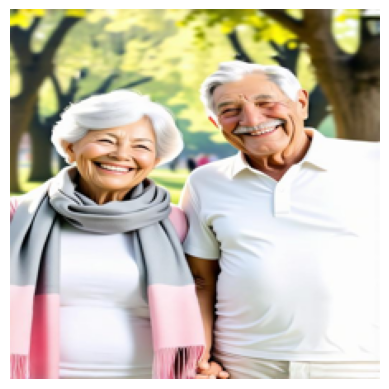

In [ ]:
#Check sau khi preprocess, ảnh có hiển thị bình thường ko
plt.imshow(img)
plt.axis('off')
plt.show()

In [32]:
#Check số lượng mẫu, phân bố của label và xem có dữ liệu thiếu ko
print("Số mẫu:", len(data))
print("Giá trị label:", data['label'].value_counts())
print("Thiếu dữ liệu:", data[['file_name', 'label']].isna().sum().sum())

Số mẫu: 79950
Giá trị label: label
1    39975
0    39975
Name: count, dtype: int64
Thiếu dữ liệu: 0
